# 5.2 · 均值-方差模型：Markowitz · 有效前沿

> 现代投资组合理论（MPT，Markowitz，1952，诺贝尔奖）是组合构建的理论基石：**在给定风险下追求最大收益，或在给定收益下追求最小风险。**
> 本节理解均值-方差框架和有效前沿，并认识它在实践中的最大敌人——**估计误差**。

## 一、组合的收益与风险

设权重向量 $w$（$\sum w_i = 1$）：
- **组合期望收益**：$\mu_p = w^\top \mu$，其中 $\mu$ 是各股票期望收益；
- **组合方差（风险）**：$\sigma_p^2 = w^\top \Sigma w$，其中 $\Sigma$ 是收益协方差矩阵；
- 组合风险不仅取决于个股，还取决于股票间的**协方差（分散化的来源）**。

> 同时持有两只低相关的股票，组合风险可以低于单只股票——这就是分散化。

## 二、均值-方差优化

**最小方差组合**（在目标收益下）：
$$\min_w \; w^\top \Sigma w \quad \text{s.t.} \; w^\top\mu = r_0,\; \sum w = 1,\; w \ge 0$$

这是一个**凸二次规划（QP）**，可用 cvxpy 精确求解。

## 三、有效前沿（Efficient Frontier）

对所有可能的目标收益求解最小方差，得到"收益-风险"曲线：
- **有效前沿**：在每个风险水平下收益最高的组合集合（曲线的左上边界）；
- 理性投资者只在有效前沿上选择；
- **全局最小方差组合**：前沿最左端；
- **切点组合（最大夏普）**：前沿上 $\mu/\sigma$ 最大的点。

投资者根据自己的**风险厌恶程度**（效用 $U = \mu_p - \frac{\lambda}{2}\sigma_p^2$，$\lambda$ 为风险厌恶系数）在前沿上选点。

## 四、实测：用 cvxpy 画有效前沿（代码在 portfolio_lab.optimize）

In [1]:
import sys, numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import qlib
from qlib.data import D
import config
from portfolio_lab.optimize import (efficient_frontier, max_sharpe,
                                   min_variance_portfolio)
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = D.list_instruments(D.instruments('all'), as_list=True, freq='day')
F = D.features(codes, ['$close'], freq='day')
close = F['$close'].unstack('instrument')
ret = close.pct_change().dropna(how='all')
win = ret.iloc[-250:]
mu = win.mean() * 242
Sigma = (win.cov() * 242)
valid = mu.notna() & Sigma.notna().all()
mu, Sigma = mu[valid], Sigma.loc[valid, valid]

front = efficient_frontier(mu.values, Sigma.values, n_points=20)
fr = np.array([p[0] for p in front]); fv = np.array([p[1] for p in front])
sh, br, bv, _ = max_sharpe(front)
print('有效前沿点数:', len(front))
print('最大夏普组合（样本内）: 夏普 %.2f  年化收益 %.2f  波动 %.2f' % (sh, br, bv))

[25036:MainThread](2026-10-30 01:34:55,646) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[25036:MainThread](2026-10-30 01:34:57,089) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[25036:MainThread](2026-10-30 01:34:57,090) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


有效前沿点数: 20
最大夏普组合（样本内）: 夏普 4.39  年化收益 0.41  波动 0.09


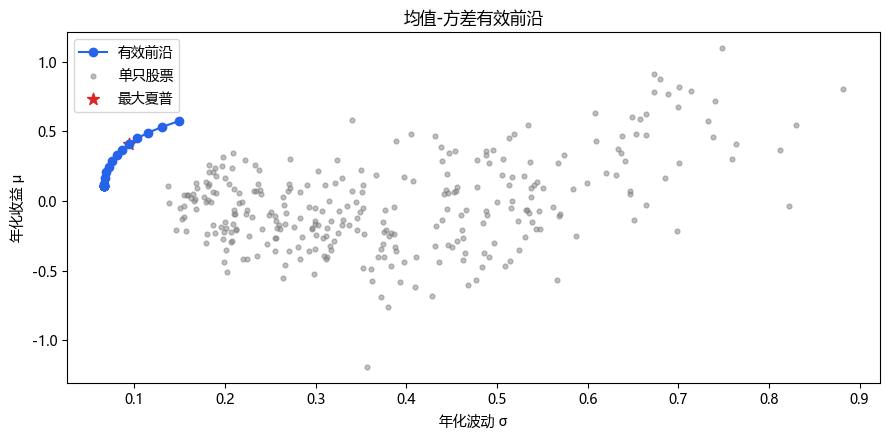

In [2]:
# 画有效前沿 + 单只股票
plt.figure(figsize=(9, 4.5))
plt.plot(fv, fr, '-o', color='#2563eb', label='有效前沿')
plt.scatter(np.sqrt(np.diag(Sigma)), mu, s=12, color='gray', alpha=.5, label='单只股票')
plt.scatter(bv, br, s=80, color='#dc2626', marker='*', label='最大夏普')
plt.xlabel('年化波动 σ'); plt.ylabel('年化收益 μ'); plt.legend()
plt.title('均值-方差有效前沿'); plt.tight_layout(); plt.show()

## 五、最大的敌人：估计误差（务必理解）

上面的"最大夏普 4+"**严重虚高，不能当真**，原因：
- 我们用**历史均值**当预期收益、用样本协方差当真实协方差——这些都是**估计值，误差很大**；
- 优化器会**放大估计误差**：给那些"恰好历史收益高、历史波动小"的股票最大权重（可能纯属偶然），这被称为 **"误差最大化"（error maximization）**；
- 样本内最优组合，样本外往往表现很差，甚至不如简单等权。

> 金融数据里，**预期收益（mu）极难估计且最重要，协方差（Sigma）相对好估计**。这就是为什么实践中常说"均值-方差优化很脆弱"。

## 六、实践中的稳健做法

1. **预期收益不要用历史均值**：用模型（因子/ML）预测，或干脆只做风险优化（最小方差、风险平价）；
2. **协方差收缩（shrinkage）**：把样本协方差向结构化矩阵（如对角、单因子）收缩，如 Ledoit-Wolf；
3. **因子风险模型**：用 Barra 类因子模型估计协方差（$\Sigma = B\Sigma_f B^\top + D$），更稳定（5.3）；
4. **加约束**：限制单票、行业、换手权重，避免极端解；
5. **用足够长的历史 + 样本外验证**。

> 后续 5.3 风险模型、5.4 约束优化会把这些落地。

## 七、小结与面试要点

- 组合收益 $w^\top\mu$，风险 $w^\top\Sigma w$；均值-方差是凸二次规划，cvxpy 求解。
- 有效前沿是风险-收益最优组合集合；风险厌恶决定选点。
- **最大敌人是估计误差**：历史均值/样本协方差不准，优化器放大误差；样本内最优样本外失效。
- 稳健做法：模型预测收益、协方差收缩、因子风险模型、加约束。

**面试高频：**
- 什么是有效前沿？切点组合？（答：风险-收益最优集合；最大夏普点）
- 为什么 Markowitz 优化在实践中不好用？（答：估计误差被放大，尤其 mu 难估；样本内过拟合）
- 怎么让均值-方差优化更稳健？（答：收缩协方差、因子模型、加约束、用模型预测 mu）
- 协方差矩阵怎么估计？（答：样本协方差、Ledoit-Wolf 收缩、因子模型）

## 动手练习
1. 用 120 天 vs 500 天估计，看有效前沿变化；
2. 用 Ledoit-Wolf 收缩协方差，重新画前沿；
3. 做样本外：用过去一年优化，持有下一个月，对比等权。

---
下一节 **5.3 风险模型：协方差、Barra、因子风险、特质风险**。